# RGB versus Event Camera: Controlled Cut-in Study

**Study ID:** `camera_cutin_timing_v1`  
**Purpose:** Test whether the existing event-camera abstraction provides earlier and fresher motion information during a cut-in.

A target travels alongside and ahead of the ego vehicle, then moves from the right-hand lane into the ego lane. Longitudinal speeds match, so lateral movement is isolated. This is a scripted sensor diagnostic, not a HighwayEnv lane-change maneuver or a driving-policy evaluation. The production environment, rewards, and sensors are unchanged.

All timings, noise levels, and detection rules are simulator assumptions. This study can expose their implications; it cannot validate real hardware or establish that event cameras are universally better. Run top to bottom using the project kernel.

In [1]:
from pathlib import Path
import sys, copy, json, hashlib
from dataclasses import asdict
from datetime import datetime
from zoneinfo import ZoneInfo
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "environments/sensor_highway/env.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from environments.sensor_highway import ExperimentConfig
from experiments.cutin_study_helpers import CutInSettings, run_cutin

STUDY_ID = "camera_cutin_timing_v1"
config = ExperimentConfig()
settings = CutInSettings()
SEEDS = list(range(30))
GAPS_M = [20, 40]
LATERAL_SPEEDS_M_S = [0, 1, 2, 4]  # Zero is a parallel-driving control.
print("Interpreter:", sys.executable)
display(pd.Series(asdict(settings), name="Prespecified tracker/scenario settings"))


Interpreter: .venv/bin/python


onset_s                            1.0
duration_s                         6.0
physics_hz                       100.0
lane_offset_m                      4.0
tracking_window_s                  0.4
minimum_samples                    5.0
minimum_span_s                     0.2
angular_alert_threshold_deg_s      3.0
decision_period_s                  0.5
alert_sigma_margin                 2.0
Name: Prespecified tracker/scenario settings, dtype: float64

## 1. Protocol and controls

- Ego and target both travel longitudinally at 25 m/s. Target initially sits 4 m to the right at a constant 20 or 40 m forward gap.
- Sensors activate at t=0; motion starts at t=1 s, after warm-up. Lateral speeds 1, 2, and 4 m/s span slow to rapid scripted cut-ins. Motion stops at the ego-lane center. No cut-in control stays at y=4 m.
- Target-center lane entry is defined as y=2 m. This is a declared diagnostic boundary, not a collision or vehicle-edge crossing.
- SensorSuite runs at 100 Hz with normal acquisition scheduling and delivery latency. False positives are disabled: one known target removes object association ambiguity. Noise and missed detections remain active.
- This deliberately simple scene has constant illumination, visible contrast assumed by the existing model, no occlusion, and no extra traffic. Ego-motion compensation is trivial because heading stays fixed.
- Thirty sensor-noise seeds per condition describe stochastic variation within these fixed geometries. They are not thirty independent road scenarios or evidence of real-world performance.

**Profiles:** Project defaults preserve current range/noise/timing differences. Matched coverage sets both cameras to 100 m range, 100° FoV, and 1° bearing noise, retaining native assumed timing (RGB: 20 Hz/80 ms; event: 50 Hz/20 ms). Equal timing additionally sets both to 20 Hz/80 ms. The existing modality-specific motion-dependent detection rule remains in every profile. These controls help distinguish the model's timing and detection effects; they do not calibrate them.

In [2]:
PROFILE_SENSORS = {}
for profile in ["project_defaults", "matched_coverage_native_timing", "matched_coverage_equal_timing"]:
    sensors = [copy.deepcopy(next(s for s in config.sensors if s.kind == kind)) for kind in ["rgb", "event"]]
    for sensor in sensors:
        sensor.false_positive_rate_hz = 0
        if profile != "project_defaults":
            sensor.range_m = 100
            sensor.fov_deg = 100
            sensor.bearing_std_deg = 1
        if profile == "matched_coverage_equal_timing":
            sensor.rate_hz = 20
            sensor.latency_s = .08
    PROFILE_SENSORS[profile] = sensors
profile_inventory = pd.DataFrame([{"profile": profile, **asdict(sensor)}
    for profile, sensors in PROFILE_SENSORS.items() for sensor in sensors])
display(profile_inventory[["profile", "kind", "range_m", "fov_deg", "bearing_std_deg", "rate_hz", "latency_s", "warmup_s"]])


,profile,kind,range_m,fov_deg,bearing_std_deg,rate_hz,latency_s,warmup_s
0,project_defaults,rgb,100,100,1.0,20,0.08,0.1
1,project_defaults,event,60,100,1.5,50,0.02,0.1
2,matched_coverage_native_timing,rgb,100,100,1.0,20,0.08,0.1
3,matched_coverage_native_timing,event,100,100,1.0,50,0.02,0.1
4,matched_coverage_equal_timing,rgb,100,100,1.0,20,0.08,0.1
5,matched_coverage_equal_timing,event,100,100,1.0,20,0.08,0.1


## 2. What counts as a motion cue?

A causal tracker fits bearing against **capture timestamps** over the latest 0.4 s. It requires at least five delivered detections spanning at least 0.2 s. It sees no true range, target velocity, or lane label. Bearings are unwrapped before fitting.

A toward-ego-lane cue requires estimated angular rate + two estimated standard errors to be below -3°/s. Slope uncertainty uses configured independent Gaussian bearing noise, an assumption matching this synthetic model. This is a direction-of-image-motion cue, not a general lane-change classifier. All thresholds are declared before evaluating results; no-cut-in controls measure noise-triggered alerts.

Recorded metrics:

| Metric | Meaning |
|---|---|
| First post-onset detection delay | Arrival of the first target detection captured after motion starts; RGB can already see the target before onset |
| First motion-cue delay | First qualifying alert after onset; noisy alerts are possible, so read with pre-onset/control false alerts |
| First 2 Hz cue delay | First 0.5 s decision boundary with a live qualifying estimate; shows how coarse action timing can hide sensor latency differences |
| Alert before lane entry | Fraction of all cut-in trials producing a cue before the target center crosses y=2 m; missing alerts count as failure |
| Information age | Current time minus capture time of the most recently delivered target detection; missing detections never refresh it |
| Angular-rate error | Estimated rate versus current true angular rate, at detected updates during motion, conditional on a valid estimate |
| Estimate availability | Fraction of motion ticks with enough recent delivered samples for a rate estimate |

The diagnostic track retains delivered detections independently of empty sensor packets; this is **not the production grid's fusion behavior**. Missing estimates are NaN, not zero error. No-cut-in controls have no motion-window metrics. Real lateral speed in m/s cannot be recovered from a single bearing stream without additional depth/geometry assumptions.

In [3]:
records = []
for profile, sensors in PROFILE_SENSORS.items():
    for gap in GAPS_M:
        for speed in LATERAL_SPEEDS_M_S:
            for seed in SEEDS:
                for sensor in sensors:
                    metrics, _ = run_cutin(sensor, gap, speed, seed, settings)
                    records.append({"profile": profile, **metrics})
    print("Completed:", profile, flush=True)
results = pd.DataFrame(records)
expected = len(PROFILE_SENSORS) * len(GAPS_M) * len(LATERAL_SPEEDS_M_S) * len(SEEDS) * 2
assert len(results) == expected
cutins = results[results.lateral_speed_m_s > 0].copy()
controls = results[results.lateral_speed_m_s == 0].copy()
summary = cutins.groupby(["profile", "gap_m", "lateral_speed_m_s", "kind"], sort=False).agg(
    trials=("seed", "count"), median_detection_delay_s=("first_post_onset_detection_delay_s", "median"),
    detection_available_fraction=("first_post_onset_detection_delay_s", lambda s: s.notna().mean()),
    median_alert_delay_s=("first_post_onset_motion_alert_delay_s", "median"),
    alert_available_fraction=("first_post_onset_motion_alert_delay_s", lambda s: s.notna().mean()),
    median_2hz_alert_delay_s=("first_2hz_motion_alert_delay_s", "median"),
    decision_alert_available_fraction=("first_2hz_motion_alert_delay_s", lambda s: s.notna().mean()),
    alert_before_entry_fraction=("alert_before_lane_entry", "mean"),
    pre_onset_false_alert_fraction=("pre_onset_false_alert", "mean"),
    mean_detection_age_s=("motion_mean_detection_age_s", "mean"),
    mean_trial_rate_rmse_deg_s=("motion_rate_rmse_deg_s", "mean"),
    rate_available_fraction=("motion_rate_available_fraction", "mean"))
control_summary = controls.groupby(["profile", "gap_m", "kind"], sort=False).agg(
    trials=("seed", "count"), false_alert_fraction=("control_false_alert", "mean"),
    mean_target_updates=("target_updates", "mean"))
display(summary.round(3))
display(control_summary.round(3))
print("Alert-delay medians exclude missing alerts. Read availability and false-alert rates alongside delays.")


Completed: project_defaults


Completed:

 matched_coverage_native_timing


Completed:

 matched_coverage_equal_timing


trials  \
profile                        gap_m lateral_speed_m_s kind            
project_defaults               20    1                 rgb        30   
                                                       event      30   
                                     2                 rgb        30   
                                                       event      30   
                                     4                 rgb        30   
                                                       event      30   
                               40    1                 rgb        30   
                                                       event      30   
                                     2                 rgb        30   
                                                       event      30   
                                     4                 rgb        30   
                                                       event      30   
matched_coverage_native_timing 20    1                 rgb        30   
                                                       event      30   
                                     2                 rgb        30   
                                                       event      30   
                                     4                 rgb        30   
                                                       event      30   
                               40    1                 rgb        30   
                                                       event      30   
                                     2                 rgb        30   
                                                       event      30   
                                     4                 rgb        30   
                                                       event      30   
matched_coverage_equal_timing  20    1                 rgb        30   
                                                       event      30   
                                     2                 rgb        30   
                                                       event      30   
                                     4                 rgb        30   
                                                       event      30   
                               40    1                 rgb        30   
                                                       event      30   
                                     2                 rgb        30   
                                                       event      30   
                                     4                 rgb        30   
                                                       event      30   

                                                              median_detection_delay_s  \
profile                        gap_m lateral_speed_m_s kind                              
project_defaults               20    1                 rgb                        0.08   
                                                       event                      0.04   
                                     2                 rgb                        0.08   
                                                       event                      0.04   
                                     4                 rgb                        0.08   
                                                       event                      0.04   
                               40    1                 rgb                        0.08   
                                                       event                      0.06   
                                     2                 rgb                        0.08   
                                                       event                      0.06   
                                     4                 rgb                        0.08   
                                                       event                      0.06   
matched_coverage_native_timing 20    1                 rgb       

trials false_alert_fraction  \
profile                        gap_m kind                                 
project_defaults               20    rgb        30             0.433333   
                                     event      30                  0.0   
                               40    rgb        30             0.266667   
                                     event      30                  0.0   
matched_coverage_native_timing 20    rgb        30             0.433333   
                                     event      30                  0.0   
                               40    rgb        30             0.266667   
                                     event      30                  0.0   
matched_coverage_equal_timing  20    rgb        30             0.433333   
                                     event      30                  0.0   
                               40    rgb        30             0.266667   
                                     event      30                  0.0   

                                            mean_target_updates  
profile                        gap_m kind                        
project_defaults               20    rgb                107.000  
                                     event                0.000  
                               40    rgb                 93.833  
                                     event                0.000  
matched_coverage_native_timing 20    rgb                107.000  
                                     event                0.000  
                               40    rgb                 93.833  
                                     event                0.000  
matched_coverage_equal_timing  20    rgb                107.000  
                                     event                0.000  
                               40    rgb                 93.833  
                                     event                0.000

Alert-delay medians exclude missing alerts. Read availability and false-alert rates alongside delays.


## 3. Compare detection delay, cue availability, and information age

Results below use matched coverage with the project's native timing assumptions. Differences are model predictions. Lower error over a small subset of successful estimates does not establish a better tracker; inspect availability too. No-cut-in controls are essential when judging apparent early warnings.

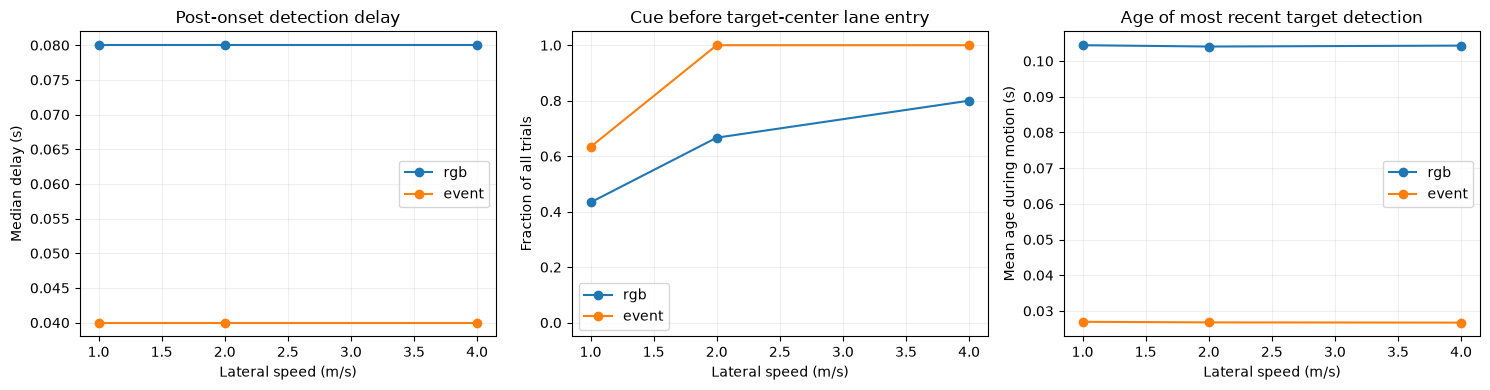

In [4]:
selected = summary.reset_index().query("profile == 'matched_coverage_native_timing' and gap_m == 20")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for kind, group in selected.groupby("kind", sort=False):
    axes[0].plot(group.lateral_speed_m_s, group.median_detection_delay_s, "o-", label=kind)
    axes[1].plot(group.lateral_speed_m_s, group.alert_before_entry_fraction, "o-", label=kind)
    axes[2].plot(group.lateral_speed_m_s, group.mean_detection_age_s, "o-", label=kind)
for ax, title, ylabel in zip(axes,
    ["Post-onset detection delay", "Cue before target-center lane entry", "Age of most recent target detection"],
    ["Median delay (s)", "Fraction of all trials", "Mean age during motion (s)"]):
    ax.set(title=title, xlabel="Lateral speed (m/s)", ylabel=ylabel)
    ax.legend(); ax.grid(alpha=.2)
axes[1].set_ylim(-.05, 1.05)
plt.tight_layout(); plt.show()


## 4. Inspect a rapid cut-in

Illustrative trace only: matched coverage, 20 m gap, 4 m/s lateral speed, one declared seed. Dashed lines mark motion onset and the target-center lane boundary. Motion estimate and detection age use delivered data only. Production policy behavior is not evaluated here.

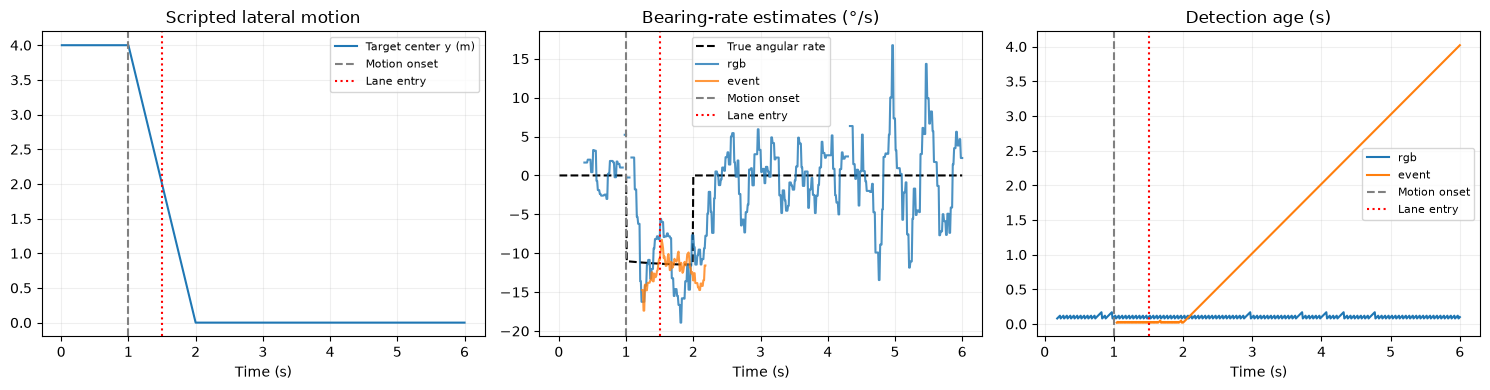

In [5]:
TRACE_SEED = SEEDS[0]
traces = []
for sensor in PROFILE_SENSORS["matched_coverage_native_timing"]:
    metrics, trace = run_cutin(sensor, 20, 4, TRACE_SEED, settings, capture=True)
    traces.append(trace.assign(kind=sensor.kind))
trace_results = pd.concat(traces, ignore_index=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
first_trace = traces[0]
axes[0].plot(first_trace.time_s, first_trace.target_y_m, label="Target center y (m)")
axes[1].plot(first_trace.time_s, first_trace.true_rate_deg_s, "k--", label="True angular rate")
for trace in traces:
    kind = trace.kind.iloc[0]
    axes[1].plot(trace.time_s, trace.estimated_rate_deg_s, label=kind, alpha=.8)
    axes[2].plot(trace.time_s, trace.last_detection_age_s, label=kind)
for ax, title in zip(axes, ["Scripted lateral motion", "Bearing-rate estimates (°/s)", "Detection age (s)"]):
    ax.axvline(settings.onset_s, color="gray", linestyle="--", label="Motion onset")
    ax.axvline(settings.onset_s + .5, color="red", linestyle=":", label="Lane entry")
    ax.set(title=title, xlabel="Time (s)"); ax.grid(alpha=.2); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 5. Conclusions and limits to record

Use the observed results to answer:
- Does native timing produce earlier/fresher target observations under matched coverage?
- Does that translate into earlier reliable motion cues, or do missed detections/noise dominate?
- Does equalizing timing remove any advantage? How does the 2 Hz consumer change cue availability?
- Are apparent early warnings also common in stationary controls?

Our earlier straight-ahead approach trials were not a test of rapid transverse motion. This study adds that missing case. It still does not model asynchronous pixels, RGB exposure blur, event optical flow, or ego-motion clutter, and therefore cannot establish the full real-world event-camera advantage. The tracker assumes one known target with independent measurement noise; production tracking would need association and more robust motion reasoning.

Any change to the actual environment or policy observations should follow these diagnostics and have a separate feature schema/model run. This notebook does not add privileged lateral velocity to policy inputs.

In [6]:
from importlib.metadata import version
output = PROJECT_ROOT / "runs/sensor_studies" / ("camera_cutin_study_" +
    datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S_%f"))
output.mkdir(parents=True, exist_ok=False)
config.save(output / "base_config.json")
for name, table in {"profiles": profile_inventory, "trials": results,
    "cutin_summary": summary.reset_index(), "control_summary": control_summary.reset_index(),
    "illustrative_trace": trace_results}.items():
    table.to_csv(output / f"{name}.csv", index=False)
source_files = ["experiments/cutin_study_helpers.py", "environments/sensor_highway/sensors.py",
                "environments/sensor_highway/weather.py", "environments/sensor_highway/config.py"]
metadata = {"study_id": STUDY_ID, "settings": asdict(settings), "seeds": SEEDS,
    "gaps_m": GAPS_M, "lateral_speeds_m_s": LATERAL_SPEEDS_M_S,
    "trace_seed": TRACE_SEED, "diagnostic_overrides": {"false_positive_rate_hz": 0},
    "status": "synthetic diagnostic; empirically uncalibrated",
    "package_versions": {k: version(k) for k in ["numpy", "pandas", "matplotlib"]},
    "source_sha256": {name: hashlib.sha256((PROJECT_ROOT / name).read_bytes()).hexdigest() for name in source_files}}
(output / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
report = "# Recorded cut-in study results\n\nSynthetic, uncalibrated model; conditional delays must be read with availability and false alerts.\n\n"
report += "## Cut-ins\n\n" + summary.round(4).to_csv() + "\n## Stationary controls\n\n" + control_summary.round(4).to_csv()
(output / "study_report.md").write_text(report)
print("Saved study:", output)
print("Completed trials:", len(results))


Saved study: runs/sensor_studies/camera_cutin_study_20261101_130503_848851
Completed trials: 1440


## First recorded interpretation

Run: `camera_cutin_study_20261101_130503_848851` (1,440 sensor trials).
The following describes this saved run, not a hardware benchmark.

For a rapid 4 m/s cut-in at 20 m forward gap with matched coverage and native timing:

| Metric | RGB | Event |
|---|---:|---:|
| Median first post-onset target detection | 80 ms | 40 ms |
| Mean age of target detection during motion | 104 ms | 27 ms |
| Median first post-onset angular-motion cue, conditional on cue | 380 ms | 270 ms |
| Cue before target-center lane entry | 24/30 | 30/30 |

Equalizing timing to 20 Hz / 80 ms removes the event timing advantage in this
case: median first target detection becomes 130 ms and motion cue 430 ms for event,
versus 80 ms and 380 ms for RGB. The event model cannot accumulate detections of the
stationary-relative target before motion; RGB can, which also affects track startup.
The project-default event range/noise settings weaken its results at 40 m compared
with matched coverage. Thus the original straight-ahead study missed a modeled
transverse-motion/timing advantage, but coverage and tracker design still matter.

**False-alert limitation:** At 20 m the RGB no-cut-in control produces at least one
motion cue in 13/30 six-second trials (43.3%); at 40 m, 8/30 (26.7%). These are
per-trial probabilities of any cue, not per-update false-positive rates. Event
controls produce zero target detections and zero cues because the current motion
rule suppresses static-relative targets by construction. This does not establish
real-world immunity to false alarms. The cue-before-entry results above are not
reliable safety-warning rates: noise alerts can contribute, and the simple tracker
needs false-alarm control before use as a policy input.

A 2 Hz consumer often reports a first available cue only at 0.5 s after onset,
masking differences of tens of milliseconds; some transient cues never coincide
with a decision boundary. Capturing fresher observations and acting sooner are
different outcomes. Real event optics, contrast, image processing, ego-motion,
and association are not validated by this diagnostic.
